## Data Science Portfolio - K Means

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler



In [20]:
data = pd.read_csv('../Resources/games_data.csv', index_col=0)
data.head(1)

,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
id,,,,,,,,,,,,,,,
TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5


In [21]:
features = ['white_rating', 'black_rating', 'opening_eco', 'opening_ply', 'turns']

X = data[features].dropna()
# Transform eco into numerical value for clustering
eco_mapping = {eco: idx for idx, eco in enumerate(sorted(X['opening_eco'].unique()))}
X['opening_eco'] = X['opening_eco'].map(eco_mapping)
print(X.head())

          white_rating  black_rating  opening_eco  opening_ply  turns
id                                                                   
TZJHLljE          1500          1191          248            5     13
l1NXvwaE          1322          1261           71            4     16
mIICvQHh          1496          1500          171            3     61
kWKvrqYL          1439          1454          241            3     61
9tXo1AUZ          1523          1469          192            5     95


In [22]:
def number_of_checks(moves):
    moves = moves.split()
    return sum(1 for move in moves if '+' in move)

def number_of_captures(moves, colour):
    moves = moves.split()
    if (colour == 'white'):
        return sum(1 for i, move in enumerate(moves) if 'x' in move and i % 2 == 0)
    return sum(1 for i, move in enumerate(moves) if 'x' in move and i % 2 == 1)


def number_of_castles(moves):
    moves = moves.split()
    return sum(1 for move in moves if 'O-O' in move or 'O-O-O' in move)



In [23]:
X['number_of_checks'] = data['moves'].apply(number_of_checks)
X['number_of_captures_white'] = data['moves'].apply(number_of_captures, colour='white')
X['number_of_captures_black'] = data['moves'].apply(number_of_captures, colour='black')
X['number_of_castles'] = data['moves'].apply(number_of_castles)

In [24]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [25]:
CLUSTER_COUNT = 4
kmeans = KMeans(n_clusters=CLUSTER_COUNT, random_state=42)

clusters = kmeans.fit_predict(X_scaled)

X['cluster'] = clusters
cluster_summary = X.groupby("cluster")[X.columns].mean()

print(cluster_summary)

         white_rating  black_rating  opening_eco  opening_ply       turns  \
cluster                                                                     
0         1451.802000   1448.582278   122.761369     3.794655   57.329270   
1         1478.343364   1457.655937   127.073478     3.905762   23.499417   
2         1862.906835   1849.930508   171.598129     6.917526   56.109393   
3         1606.095065   1611.128931   141.240203     4.682874  109.176101   

         number_of_checks  number_of_captures_white  number_of_captures_black  \
cluster                                                                         
0                4.161900                  7.446476                  7.382091   
1                1.505015                  2.655237                  2.566363   
2                2.925353                  6.721840                  6.735204   
3               11.355588                 12.142477                 12.082245   

         number_of_castles  cluster  
cluster     

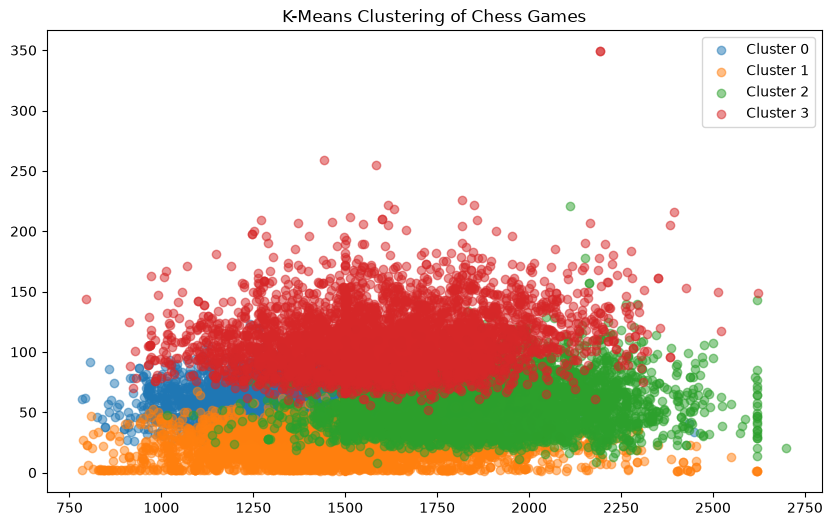

In [41]:
# Plot the clusters
plt.figure(figsize=(10, 6))
for cluster in range(CLUSTER_COUNT):
    cluster_data = X[X['cluster'] == cluster]
    plt.scatter(cluster_data['white_rating'], cluster_data['turns'], label=f'Cluster {cluster}', alpha=0.5)
plt.title('K-Means Clustering of Chess Games')
plt.legend()
plt.show()